In [2]:
data_loader = DataManager("fer2013", image_size=input_shape[:2])
faces, emotions = data_loader.get_data()
faces = preprocess_input(faces)

/home/ubuntu/Repos/miniXception_vanilla/src/utils/datasets.py:71: FutureWarning: Method .as_matrix will be removed in a future version. Use .values instead.
  emotions = pd.get_dummies(data['emotion']).as_matrix()


In [3]:
# SHUFFLE FACES AND EMOTION ARRAYS SIMULTANEOUSLY
# source: https://stackoverflow.com/questions/4601373/better-way-to-shuffle-two-numpy-arrays-in-unison
def shuffle_in_unison(a, b):
    assert len(a) == len(b)
    shuffled_a = np.empty(a.shape, dtype=a.dtype)
    shuffled_b = np.empty(b.shape, dtype=b.dtype)
    permutation = np.random.permutation(len(a))
    for old_index, new_index in enumerate(permutation):
        shuffled_a[new_index] = a[old_index]
        shuffled_b[new_index] = b[old_index]
    return (shuffled_a, shuffled_b)

faces, emotions = shuffle_in_unison(faces, emotions)
faces.shape
# faces[-1].shape

(35887, 64, 64, 1)

In [4]:
# hardcoded! TODO: pass labels value
labels = {0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy',
          4: 'sad', 5: 'surprise', 6: 'neutral'}

# count label instances
# TODO: improve from hardcode
num_classes = 7
dataset_name = "fer2013"
def count_instances(dataset, faces, emotions):
    label_indexes = []
    num_samples, num_classes = emotions.shape
#     print(num_classes)
    print("["+str(dataset)+"] Counting class instances...")
    
    # generate array for counting label instances
    instances_count = [0 for x in range(num_classes)]
    for i in range(len(emotions)):
        label_index = int((np.argwhere(emotions[i]==1)))
        label_indexes.append(label_index)
        instances_count[label_index] += 1
    
    return (instances_count, label_indexes)

# find minimum label count
classes_count, label_indexes = count_instances(dataset_name, faces, emotions)

minimum = min(classes_count)
min_index = classes_count.index(minimum)

dataset = "fer2013"
# print class per line
print("["+str(dataset)+"] (LABEL) count:")
for i in range(num_classes):
    temp = "["+str(dataset)+"]  ("+str(labels[i])+") "+str(classes_count[i])
    if i == min_index:
        temp = temp+" <--- minimum"
    print(temp)

    
# compute class weights for imbalanced data (input is train data)
labels = [emotion.argmax() for emotion in emotions]
print(minimum)

[fer2013] Counting class instances...
[fer2013] (LABEL) count:
[fer2013]  (angry) 4953
[fer2013]  (disgust) 547 <--- minimum
[fer2013]  (fear) 5121
[fer2013]  (happy) 8989
[fer2013]  (sad) 6077
[fer2013]  (surprise) 4002
[fer2013]  (neutral) 6198
547


In [5]:
dataset = "fer2013"

# get n samples from datasets
print("["+str(dataset)+"] Acquiring subsets with "+str(minimum)+" samples from each class...")
counter = [minimum for x in range(num_classes)]
subsets_faces = [[] for x in range(num_classes)]
subsets_emotions = [[] for x in range(num_classes)]

i = 0
while sum(counter) != 0:
    emotion = label_indexes[i]
    if counter[emotion] != 0:
        if subsets_faces[emotion] == []:
            temp_face = np.expand_dims(faces[i], axis=0)
            temp_emotion = np.expand_dims(emotions[i], axis=0)
            subsets_faces[emotion] = temp_face
            subsets_emotions[emotion] = temp_emotion
        else:
            temp_face = np.expand_dims(faces[i], axis=0)
            temp_emotion = np.expand_dims(emotions[i], axis=0)
            subsets_faces[emotion] = np.vstack((subsets_faces[emotion],\
                                                        temp_face))
            subsets_emotions[emotion] = np.vstack((subsets_emotions[emotion],\
                                                           temp_emotion))
        counter[label_indexes[i]] -= 1
    i += 1
#         print(counter)
print("["+str(dataset)+"] Acquired images subset with size "+str(len(subsets_faces[0]))+" per class.")
print("["+str(dataset)+"] Acquired labels subset with size "+str(len(subsets_emotions[0]))+" per class.")  


#   split data and join data of different classes in a single 4d numpy array
for i in range(num_classes):
    if i == 0:
        combined_faces = subsets_faces[i]
        combined_labels = subsets_emotions[i]
    else:
        combined_faces = np.vstack((combined_faces, subsets_faces[i]))
        combined_labels = np.vstack((combined_labels, subsets_emotions[i]))

[fer2013] Acquiring subsets with 547 samples from each class...


/usr/local/lib/python3.5/dist-packages/ipykernel_launcher.py:13: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  del sys.path[0]


[fer2013] Acquired images subset with size 547 per class.
[fer2013] Acquired labels subset with size 547 per class.


In [6]:
embeddings_1 = []
embeddings_2 = []
predictions = []
for face in combined_faces:
    # try:
    #     face = cv2.resize(face, (self._emotion_target_size))
    # except:
    #     continue

    # gray_face = preprocess_input(gray_face, True)
    face = np.expand_dims(face, 0)
    # face = np.expand_dims(face, -1)
    scores = base_classifier.predict(face)
    label_arg = np.argmax(scores)
    embedding_1 = add_4_classifier.predict(face).flatten()
    embedding_2 = conv2d_7_classifier.predict(face).flatten()
    
    predictions.append(label_arg)
    embeddings_1.append(embedding_1)
    embeddings_2.append(embedding_2)
print(embeddings_1[-1].shape)
print(embeddings_2[-1].shape)

(2048,)
(112,)


In [7]:
# create color labels
labels_subset = [label.argmax() for label in combined_labels]

colors = {0: 'red', 1: 'green', 2: 'violet', 3: 'yellow',
          4: 'DarkBlue', 5: 'LightBlue', 6: 'pink'}

labels = {0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy',
          4: 'sad', 5: 'surprise', 6: 'neutral'}

color_labels = []
for i, label in enumerate(labels_subset):
    color_labels.append(colors[label])

color_predictions = []
for i, label in enumerate(predictions):
    color_predictions.append(colors[label])

In [8]:
len(color_labels)
len(color_predictions)

3829

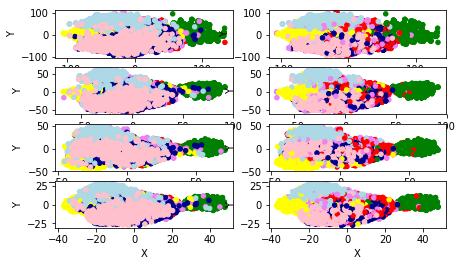

In [14]:
from time import time

import matplotlib.pyplot as plt
import pandas as pd
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import NullFormatter

from sklearn.manifold import TSNE
from sklearn import datasets

n_points = 2000
n_neighbors = 2
n_components = 2
perplexities = [5, 30, 50, 100]

fig, axes = plt.subplots(nrows=4, ncols=2)

# CONV2D_7 layer embeddings
for i, perplexity in enumerate(perplexities):
    t0 = time()
    tsne = TSNE(n_components=n_components, init='pca', random_state=0, perplexity = perplexity)
    # TODO: Randomize n_points sampled
    Y = tsne.fit_transform(embeddings_2)
    t1 = time()
    conv2d_7_df = pd.DataFrame(Y, columns=["X", "Y"])
    ax1 = conv2d_7_df.plot.scatter(x='X',
                            y='Y',
                            c=color_labels,
                            ax=axes[i,0],
                            figsize=(7,4))
    
for i, perplexity in enumerate(perplexities):
    t0 = time()
    tsne = TSNE(n_components=n_components, init='pca', random_state=0, perplexity = perplexity)
    # TODO: Randomize n_points sampled
    Y = tsne.fit_transform(embeddings_2)
    t1 = time()
    conv2d_7_df = pd.DataFrame(Y, columns=["X", "Y"])
    ax1 = conv2d_7_df.plot.scatter(x='X',
                            y='Y',
                            c=color_predictions,
                            ax=axes[i,1],
                            figsize=(7,4))
    
# first column: actual labels
# second column:  predicted labels

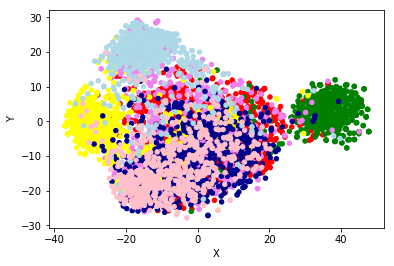

In [15]:
ax1 = conv2d_7_df.plot.scatter(x='X',
                        y='Y',
                        c=color_labels)

KeyboardInterrupt: 

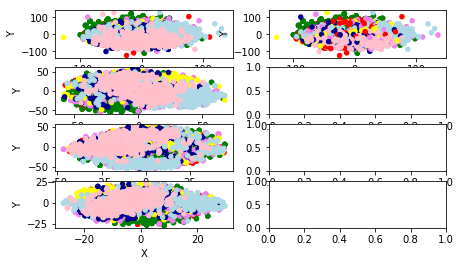

In [10]:
# ADD_4 layer embeddings

fig2, axes2 = plt.subplots(nrows=4, ncols=2)

for i, perplexity in enumerate(perplexities):
    t0 = time()
    tsne = TSNE(n_components=n_components, init='pca', random_state=0, perplexity = perplexity)
    # TODO: Randomize n_points sampled
    Y = tsne.fit_transform(embeddings_1)
    t1 = time()
    add_4_df = pd.DataFrame(Y, columns=["X", "Y"])
    ax1 = add_4_df.plot.scatter(x='X',
                            y='Y',
                            c=color_labels,
                            ax=axes2[i,0],
                            figsize=(7,4))
    
for i, perplexity in enumerate(perplexities):
    t0 = time()
    tsne = TSNE(n_components=n_components, init='pca', random_state=0, perplexity = perplexity)
    # TODO: Randomize n_points sampled
    Y = tsne.fit_transform(embeddings_1)
    t1 = time()
    add_4_df = pd.DataFrame(Y, columns=["X", "Y"])
    ax1 = add_4_df.plot.scatter(x='X',
                            y='Y',
                            c=color_predictions,
                            ax=axes2[i,1],
                            figsize=(7,4))
    
# first column: actual labels
# second column:  predicted labels

In [ ]:
conv2d_7_df

In [ ]:
add_4_df

In [ ]:
# pandas scatterplot
import pandas as pd

def label_point(embeddings_x, embeddings_y, labels, ax):
    a = pd.concat({'embeddings_x': embeddings_x, 'embeddings_y': embeddings_y, 'labels': labels}, axis=1)
    for i, point in a.iterrows():
        ax.text(point['embeddings_x'], point['embeddings_y'], str(point['labels']))

# ADD_4 layer embeddings
perplexities = [5, 30, 50, 100]
for i, perplexity in enumerate(perplexities):
    t0 = time()
    tsne = TSNE(n_components=n_components, init='pca', random_state=0, perplexity = perplexity)
    # TODO: Randomize n_points sampled
    Y = tsne.fit_transform(embeddings_1)
    t1 = time()
#     add_4_df = pd.DataFrame({'x':Y[:,0], 'y':Y[:,0]}, 
#                   index=labels_subset)
    input_data = {'embeddings_x':Y[:,0],
                  'embeddings_y':Y[:,1],
                 'labels':labels_subset}
    add_4_df = pd.DataFrame(input_data, columns=['embeddings_x', 'embeddings_y', 'labels'])
    ax1 = add_4_df.plot.scatter(x='embeddings_x',
                                y='embeddings_y',
                                c=color_labels)
#                             figsize=(20,10))
    ax = add_4_df.set_index('embeddings_x')['embeddings_y'].plot(style='o')

    label_point(add_4_df.embeddings_x, add_4_df.embeddings_y, add_4_df.labels, ax)
# ax = add_4_df.set_index('embeddings_x')['embeddings_y'].plot(style='o')

In [ ]:
print(__doc__)

from time import time

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import NullFormatter

from sklearn.manifold import TSNE
from sklearn import datasets

# Next line to silence pyflakes. This import is needed.
Axes3D
n_points = 2000
n_neighbors = 2
n_components = 2

fig = plt.figure(figsize=(15, 20))
plt.suptitle("Manifold Learning with %i points, %i neighbors"
             % (n_points, n_neighbors), fontsize=14)
n_components = 2

# ADD_4 layer embeddings
perplexities = [5, 30, 50, 100]
for i, perplexity in enumerate(perplexities):
    t0 = time()
    tsne = TSNE(n_components=n_components, init='pca', random_state=0, perplexity = perplexity)
    # TODO: Randomize n_points sampled
    Y = tsne.fit_transform(embeddings_1[:n_points])
    t1 = time()
    
    
    ax = fig.add_subplot(5, 2, 2*i+1)
    plt.scatter(Y[:, 0], Y[:, 1], cmap=plt.cm.Spectral)
    plt.title("[t-SNE] add_4 (%d) (%.2g sec)" %  (perplexity, t1 - t0))
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    plt.axis('tight')


# CONV_2D_7 layer embeddings
for i, perplexity in enumerate(perplexities):
    t0 = time()
    tsne = TSNE(n_components=n_components, init='pca', random_state=0, perplexity = perplexity)
    # TODO: Randomize n_points sampled
    Y = tsne.fit_transform(embeddings_2[:n_points])
    t1 = time()

    ax = fig.add_subplot(5, 2, 2*i+2)
    plt.scatter(Y[:, 0], Y[:, 1], cmap=plt.cm.Spectral)
    plt.title("[t-SNE] conv2d_7 (%d) (%.2g sec)" % (perplexity, t1 - t0))
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    plt.axis('tight')
    
plt.show()